---
## Step 0 — Imports

In [20]:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path

import os
import scipy.io
import scanpy as sc
import anndata as ad
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

sc.settings.verbosity = 2  # show INFO messages from scanpy
sc.settings.set_figure_params(dpi=100, facecolor="white")

print(f"scanpy  version: {sc.__version__}")
print(f"anndata version: {ad.__version__}")
print(f"pandas  version: {pd.__version__}")
print(f"numpy   version: {np.__version__}")

from besca_sc import filter_cells_and_genes, subset_adata, qc
from besca_sc import get_threshold, calculate_thresholds
from besca_sc import plot_thresholds
from besca_sc.paths import (
    EXTERNAL_DIR,
    INTERIM_DIR,
    PROCESSED_DIR,
    RAW_DIR,
    RESULTS_DIR,
)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
scanpy  version: 1.12.4
anndata version: 0.13.4
pandas  version: 3.0.6
numpy   version: 2.5.4


/var/folders/22/sjkvvcj17_gdnvz15k1nj1800000gn/T/ipykernel_79700/3760991807.py:15: FutureWarning: The method set_figure_params is deprecated and will be removed in the future. Use :func:`scanpy.set_figure_params` instead
  sc.settings.set_figure_params(dpi=100, facecolor="white")
/var/folders/22/sjkvvcj17_gdnvz15k1nj1800000gn/T/ipykernel_79700/3760991807.py:17: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  print(f"scanpy  version: {sc.__version__}")
/var/folders/22/sjkvvcj17_gdnvz15k1nj1800000gn/T/ipykernel_79700/3760991807.py:18: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  print(f"anndata version: {ad.__version__}")


In [21]:
SAMPLE_KEY = "sample_id"

---
## Step 1 — Load the merged AnnData

In [22]:
adata = sc.read_h5ad(f"{PROCESSED_DIR}/doublet_called.h5ad")
print(adata)
print(f"\n{adata.n_obs} cells  x  {adata.n_vars} genes")

AnnData object with n_obs × n_vars = 21870 × 38606
    obs: 'htodemux_Assignment', 'multiseq_Assignment', 'hasheddrops_Assignment', 'gmmdemux_Assignment', 'hashsolo_Assignment', 'bff_consensuscall_Assignment', 'demuxmix_Assignment', 'Consensus_Assignment', 'Confidence', 'Consensus_DropletType', 'Donor', 'stimulation', 'library', 'sample_id', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'scrublet_score', 'scrublet_predicted_doublet', 'solo_doublet_probability', 'solo_prediction', 'is_doublet'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    uns: 'doublet_detection', 'sample_id_colors'
    obsm: 'X_pca', 'X_umap'
    layers: 'counts', None (.X)

21870 cells  x  38606 genes


---
## Step 2 — Obtain thresholds for MAD

In [23]:
# Define metric bounds and number of median absolute deviations (NMADs) for QC thresholds
metric_bounds = {
    "total_counts": (500, 20000),
    "n_genes_by_counts": (500, None),
    "pct_counts_mt": (None, 20),
}
nmads = {
    "total_counts": 3,
    "n_genes_by_counts": 3,
    "pct_counts_mt": 3,
}

# Compute global thresholds
global_thresholds = calculate_thresholds(
    adata,
    metric_bounds=metric_bounds,
    nmads=nmads,
)

# Compute per-sample thresholds
per_sample_thresholds = {
    sample:
        calculate_thresholds(
            subset_adata(adata, mask=adata.obs[SAMPLE_KEY].eq(sample)),
            metric_bounds=metric_bounds,
            nmads=nmads,
        ) for sample in adata.obs[SAMPLE_KEY].unique()
}

---
## Step 3 — Visualise QC distributions

Look at these plots **before** setting any thresholds.  
The distributions guide the choice of cutoffs in Step 4.

### Global thresholds

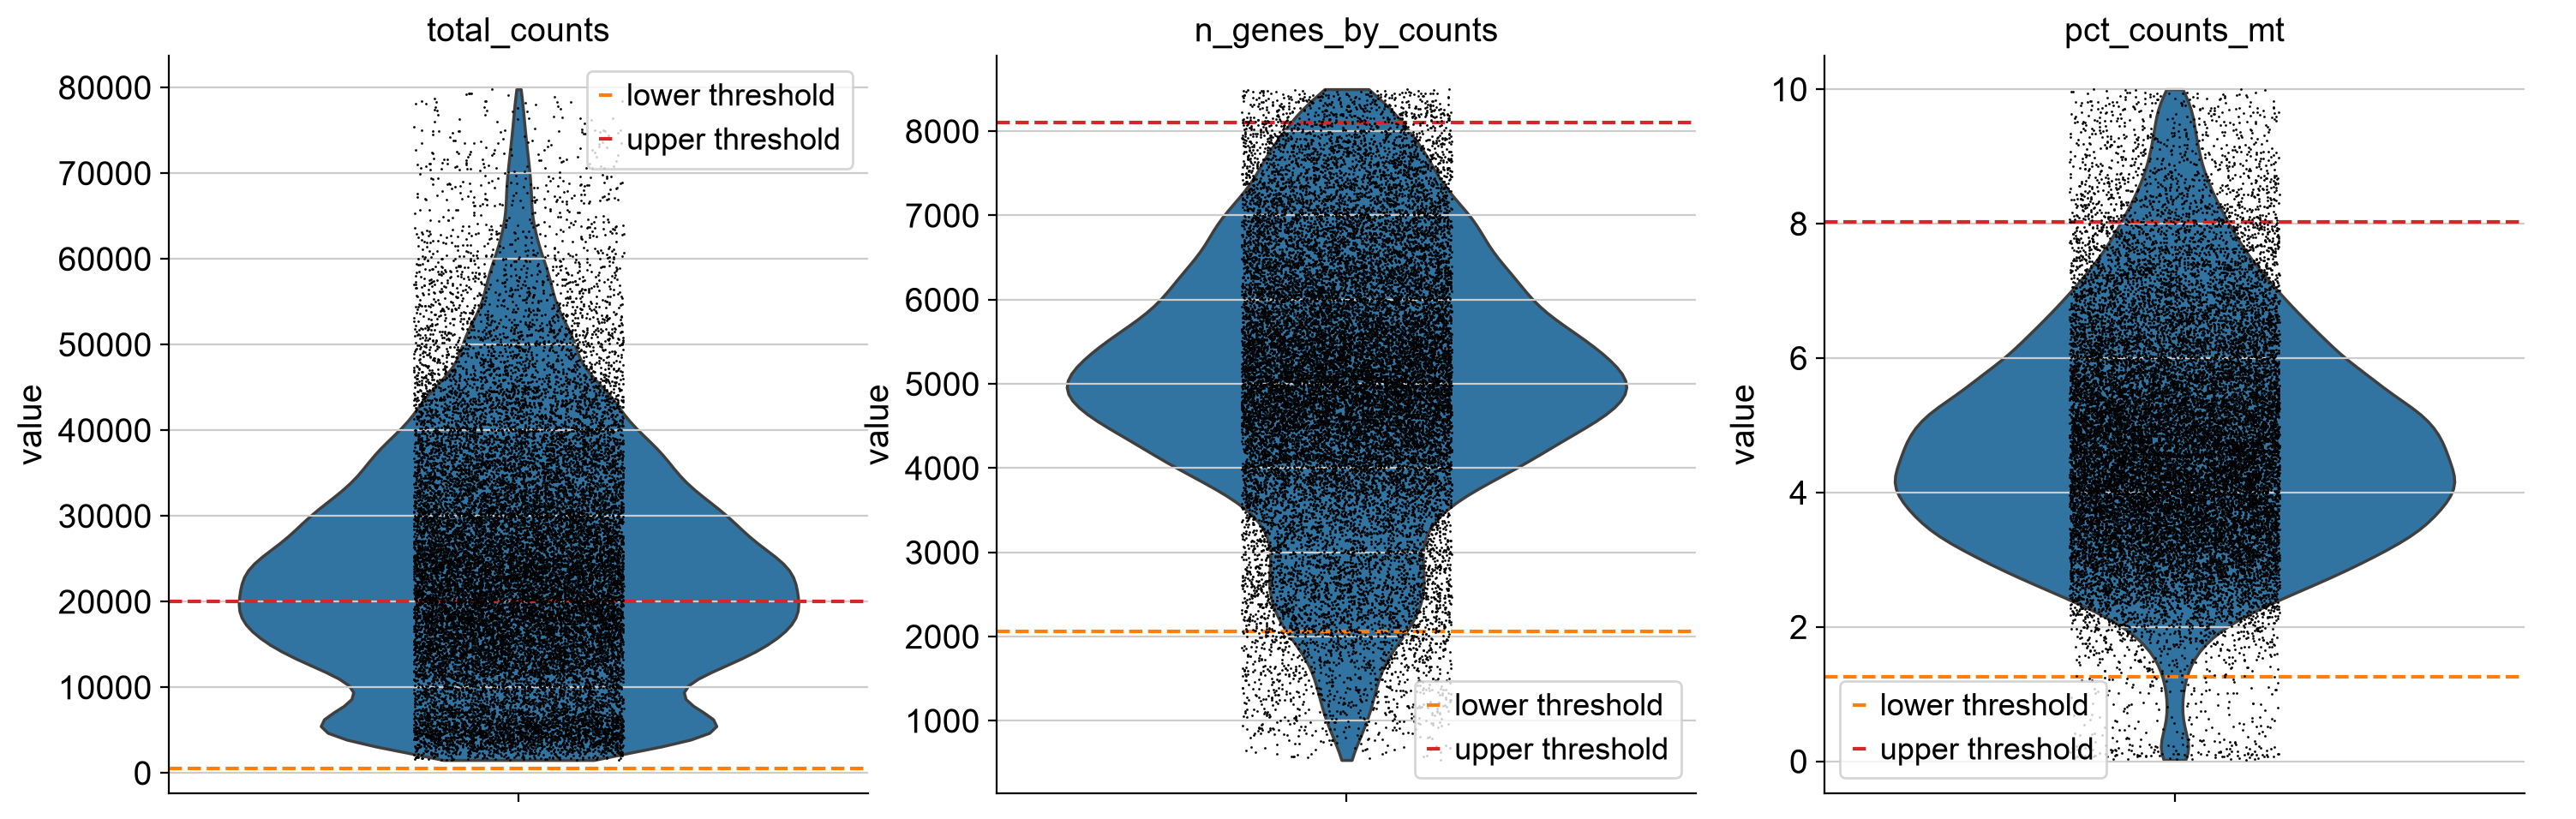

In [24]:
fig, axes = plot_thresholds(
    adata,
    thresholds=global_thresholds,
)

### Per-sample thresholds

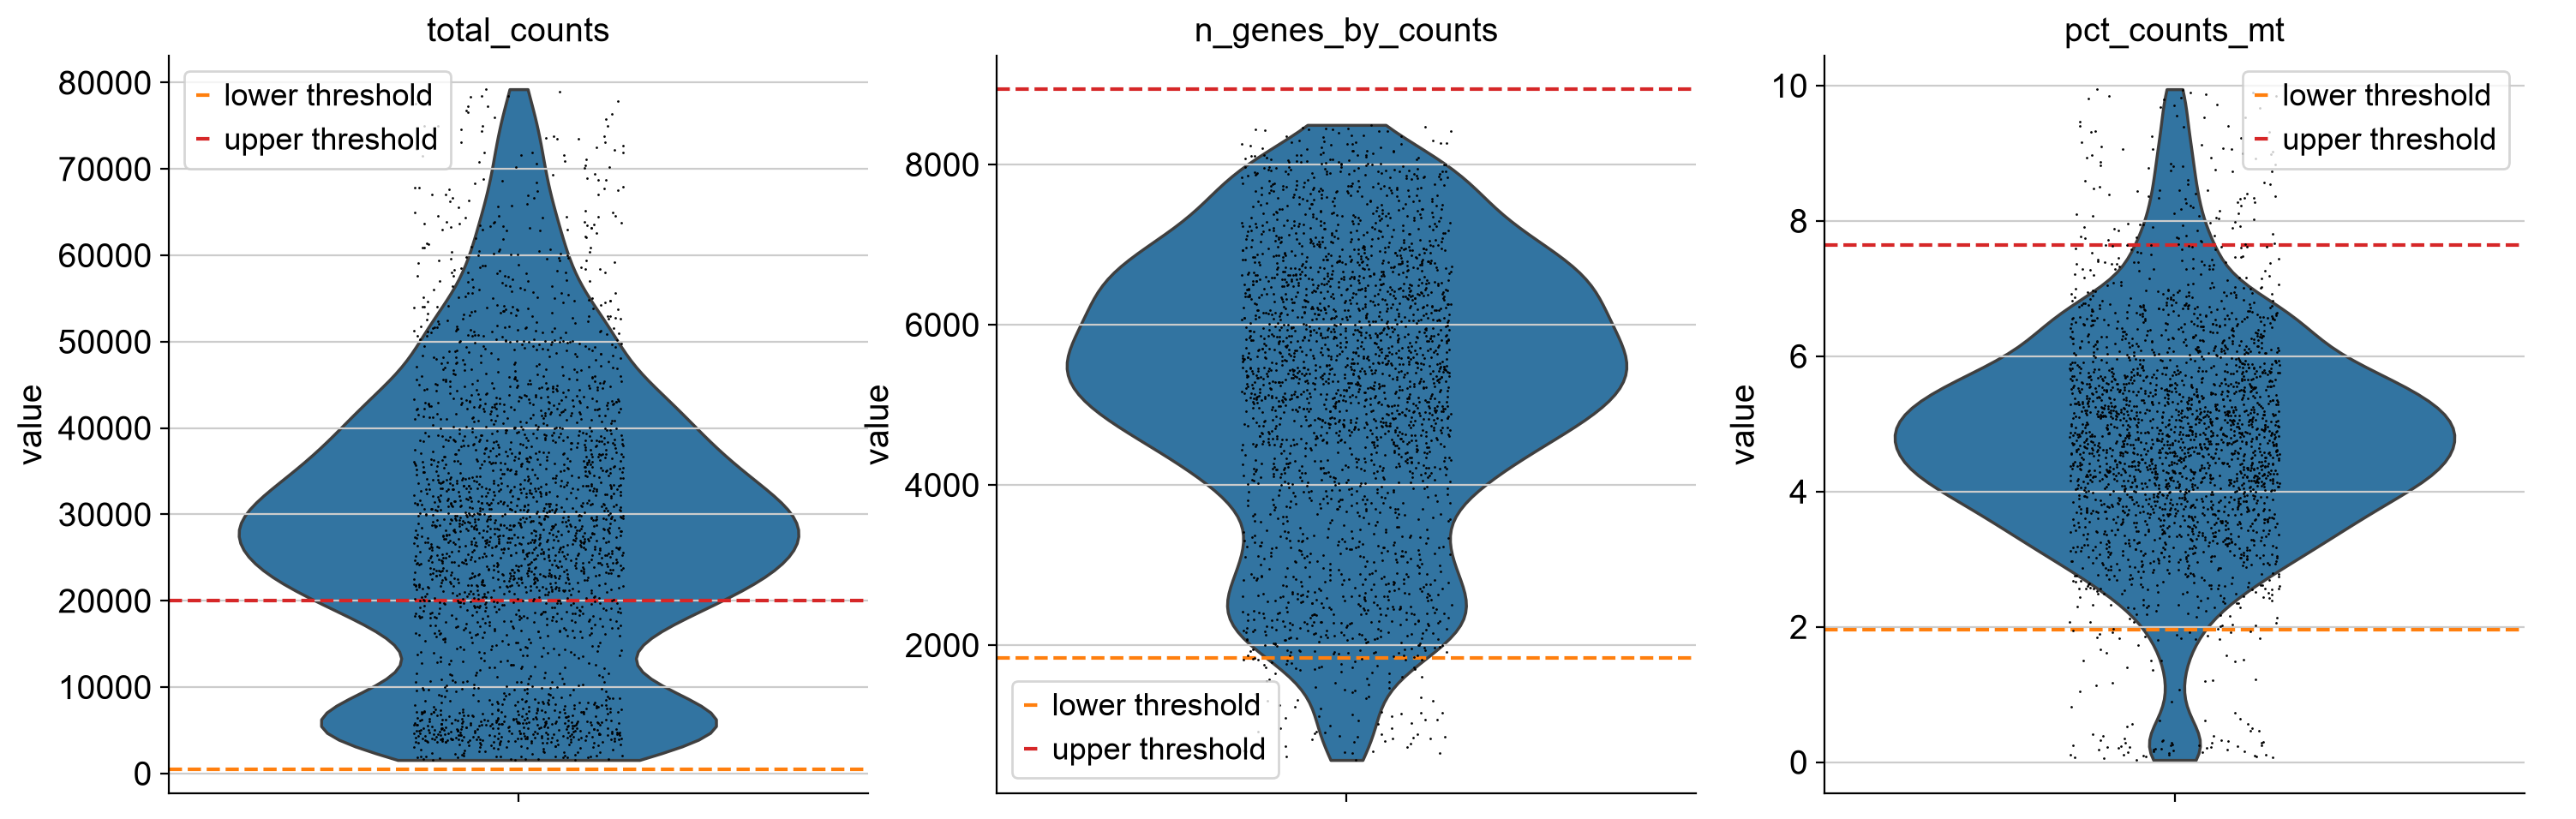

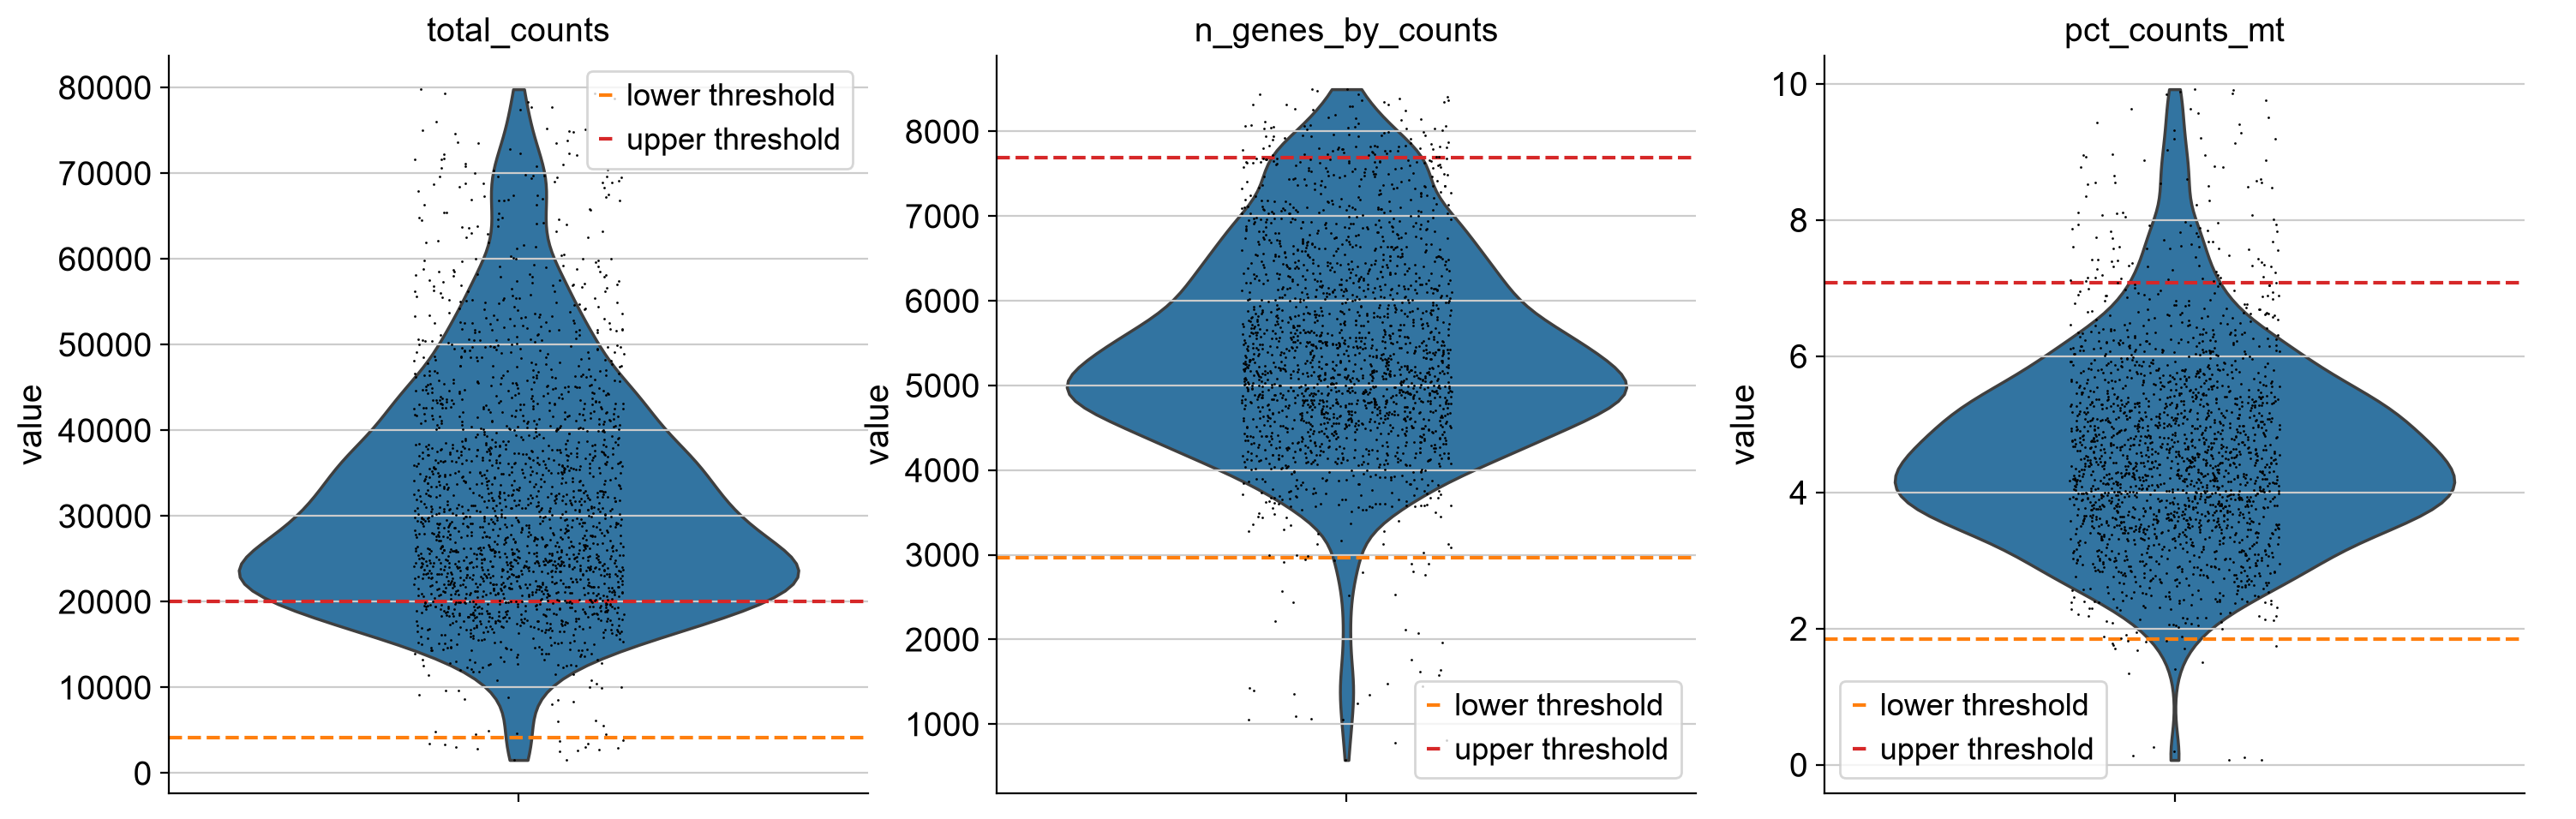

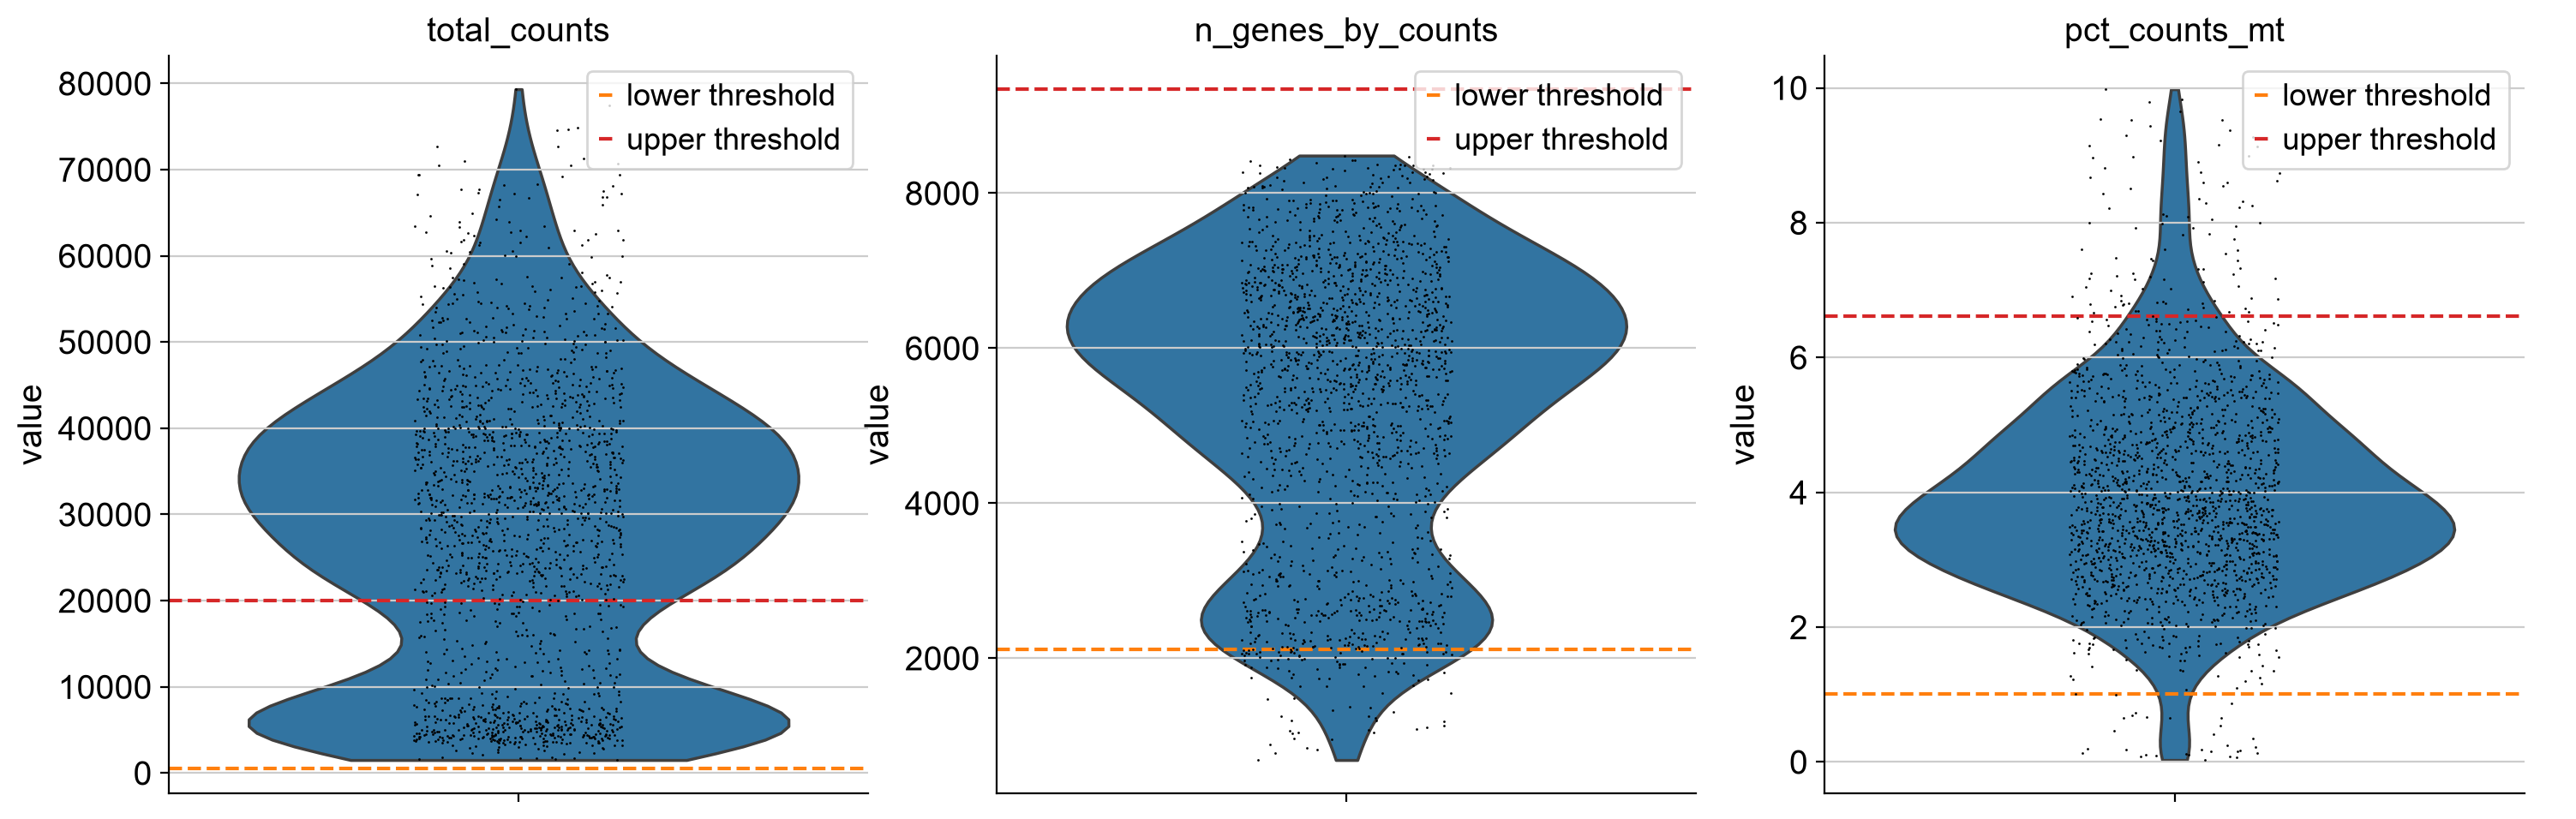

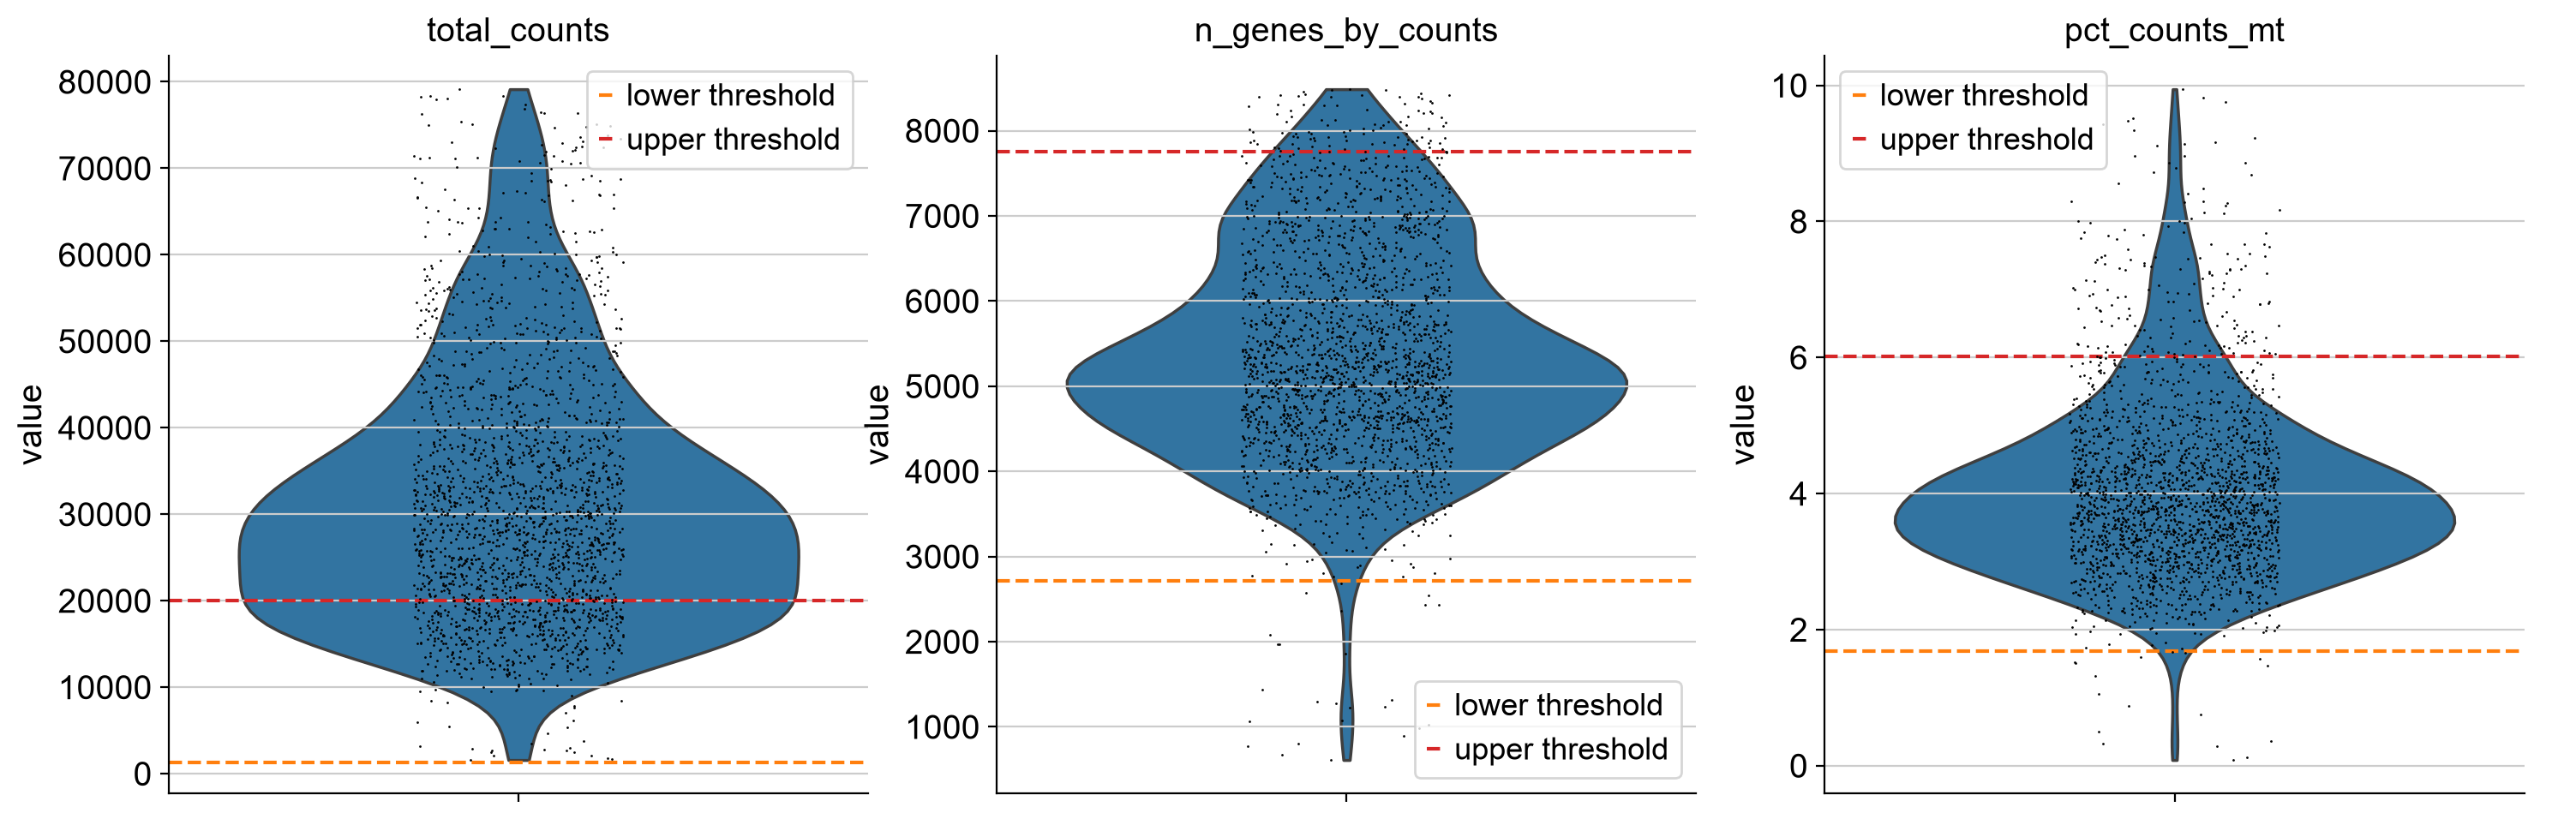

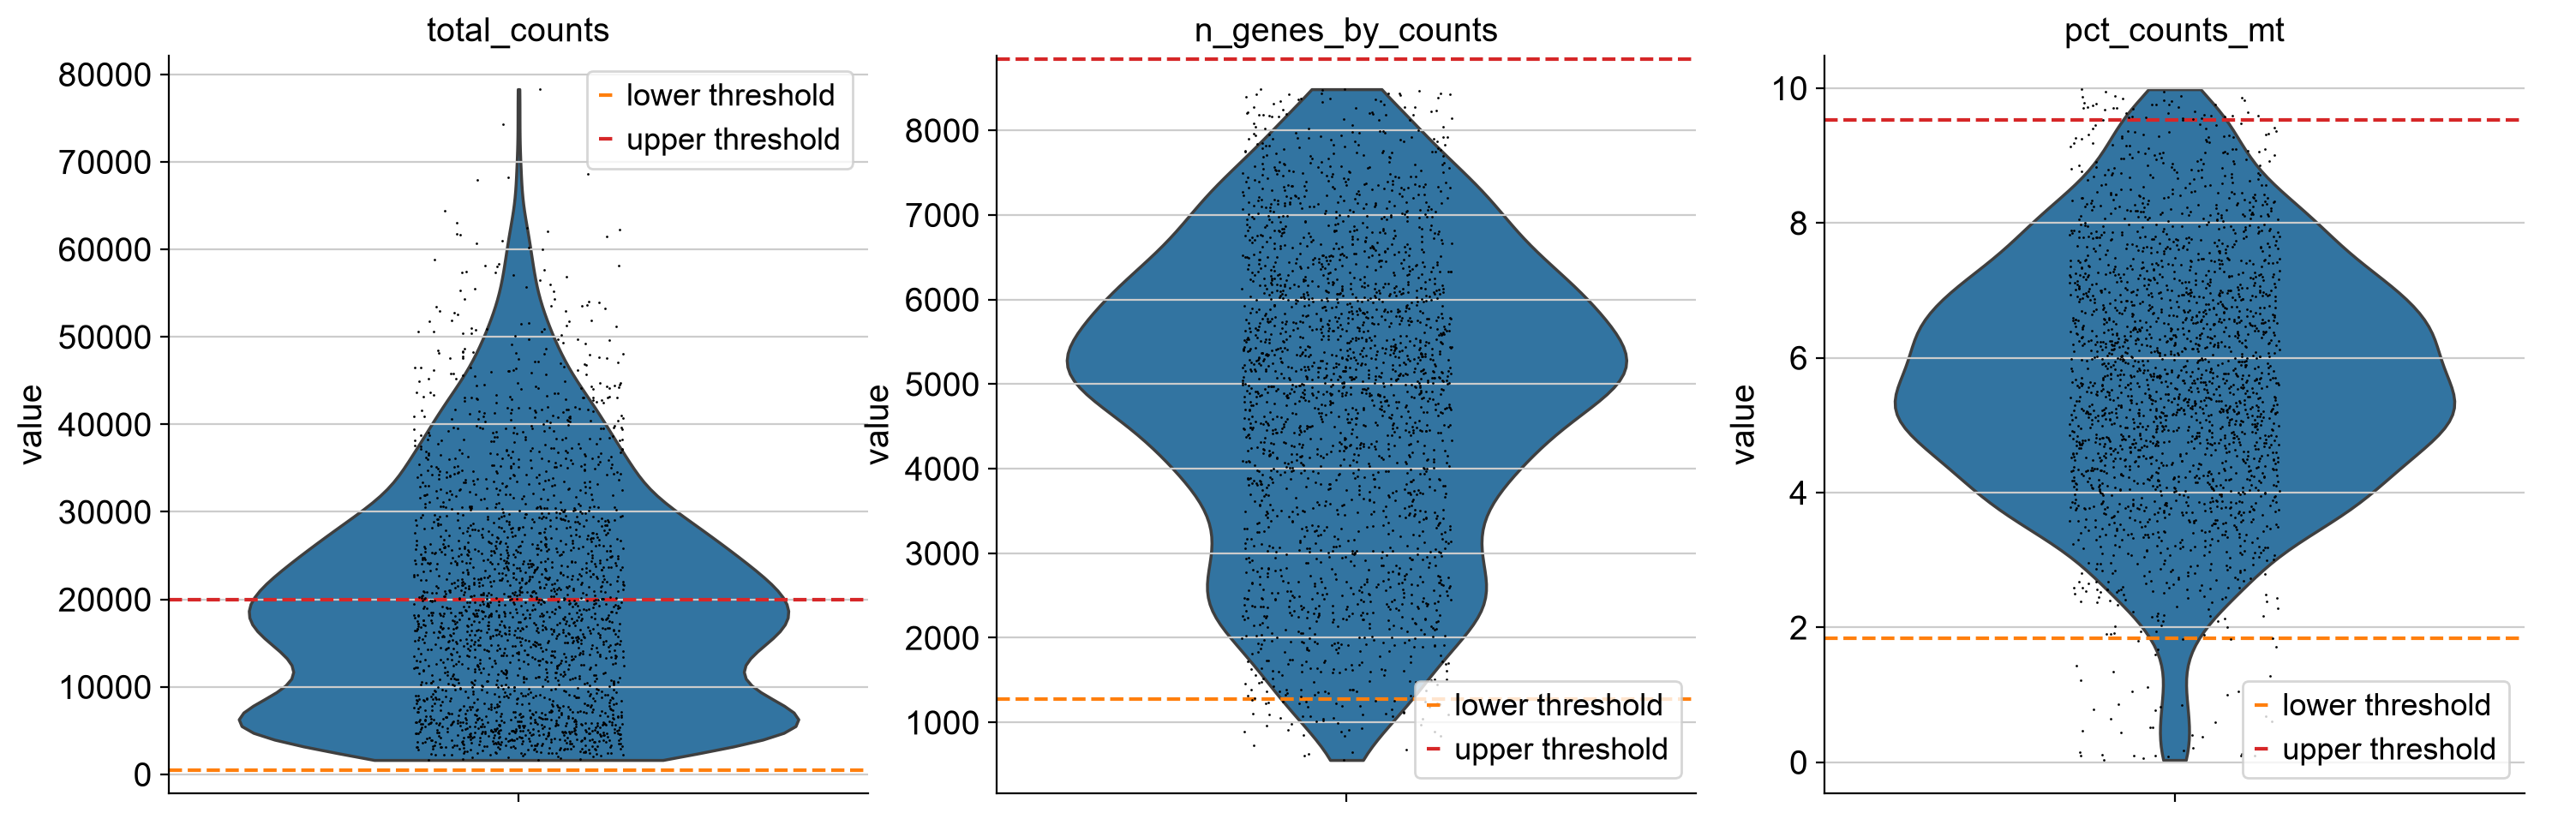

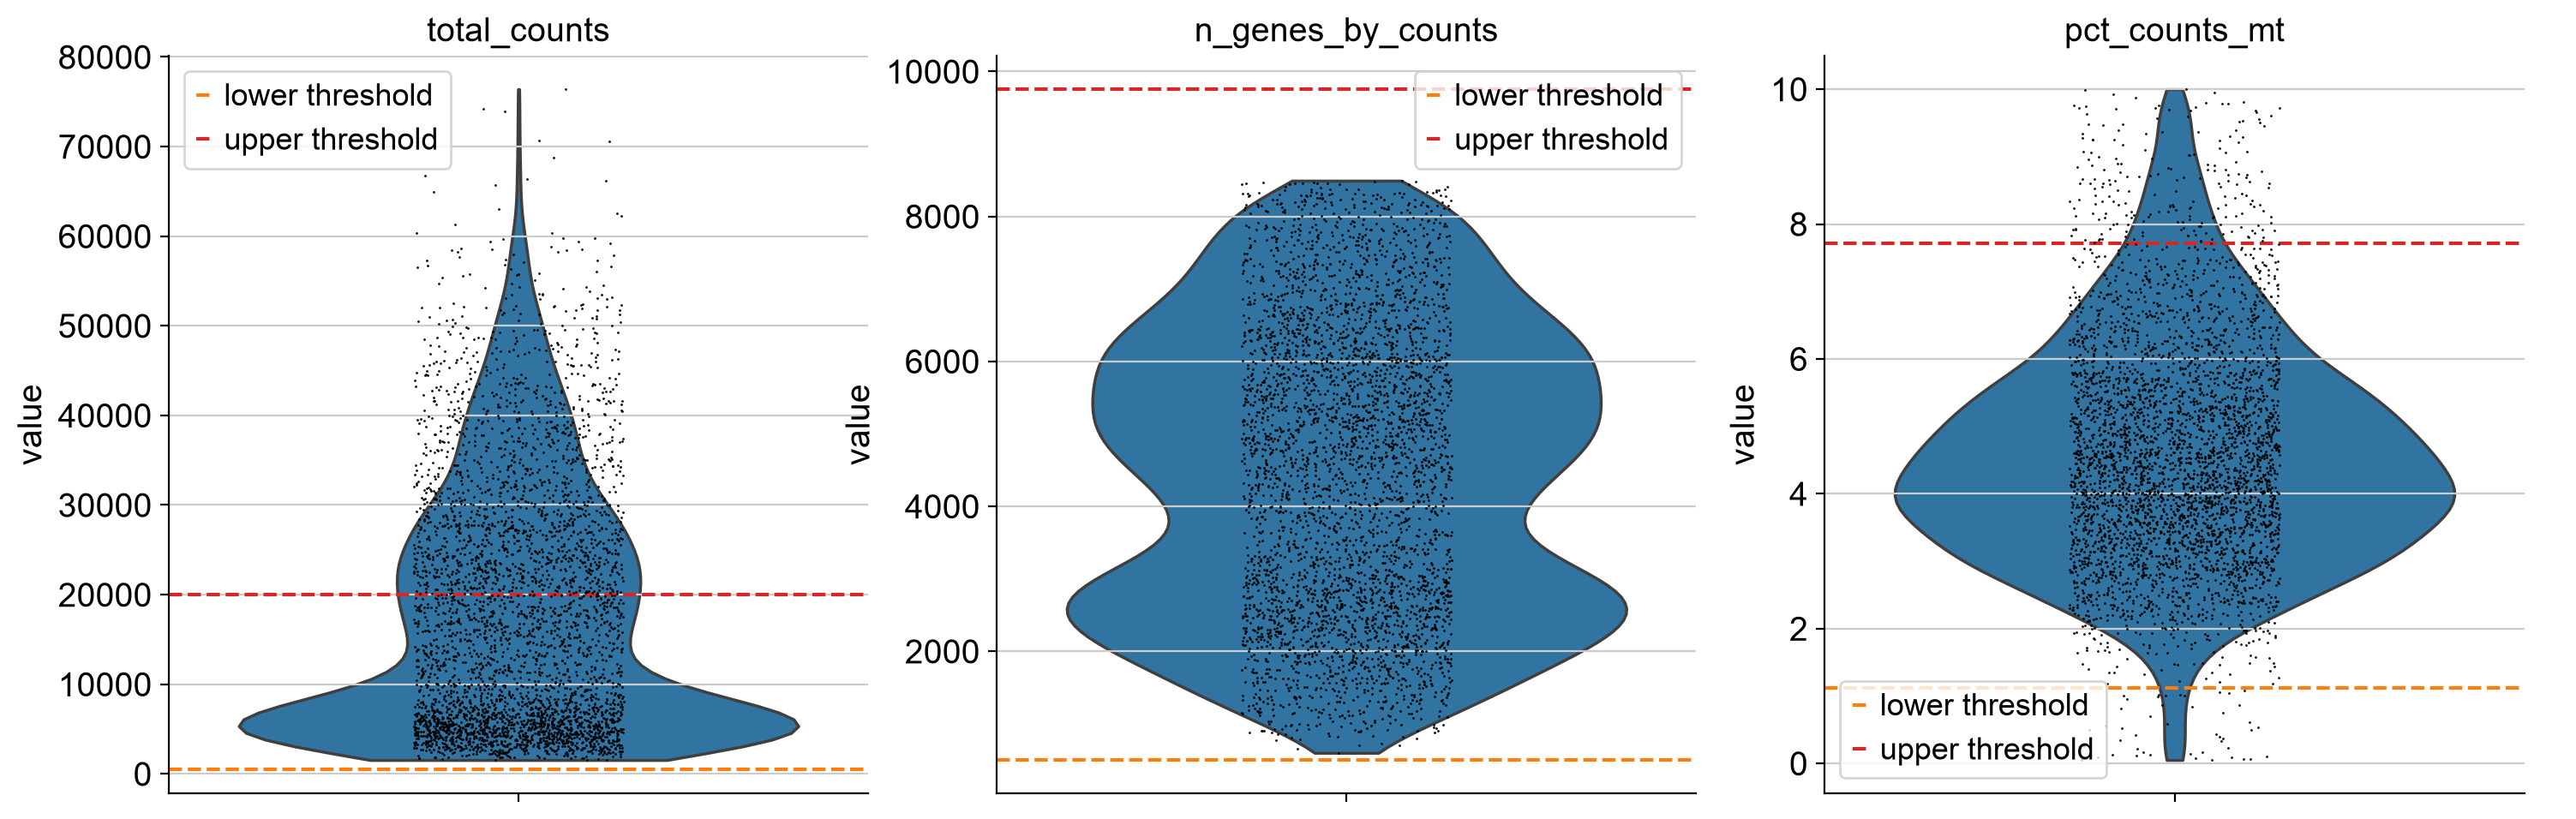

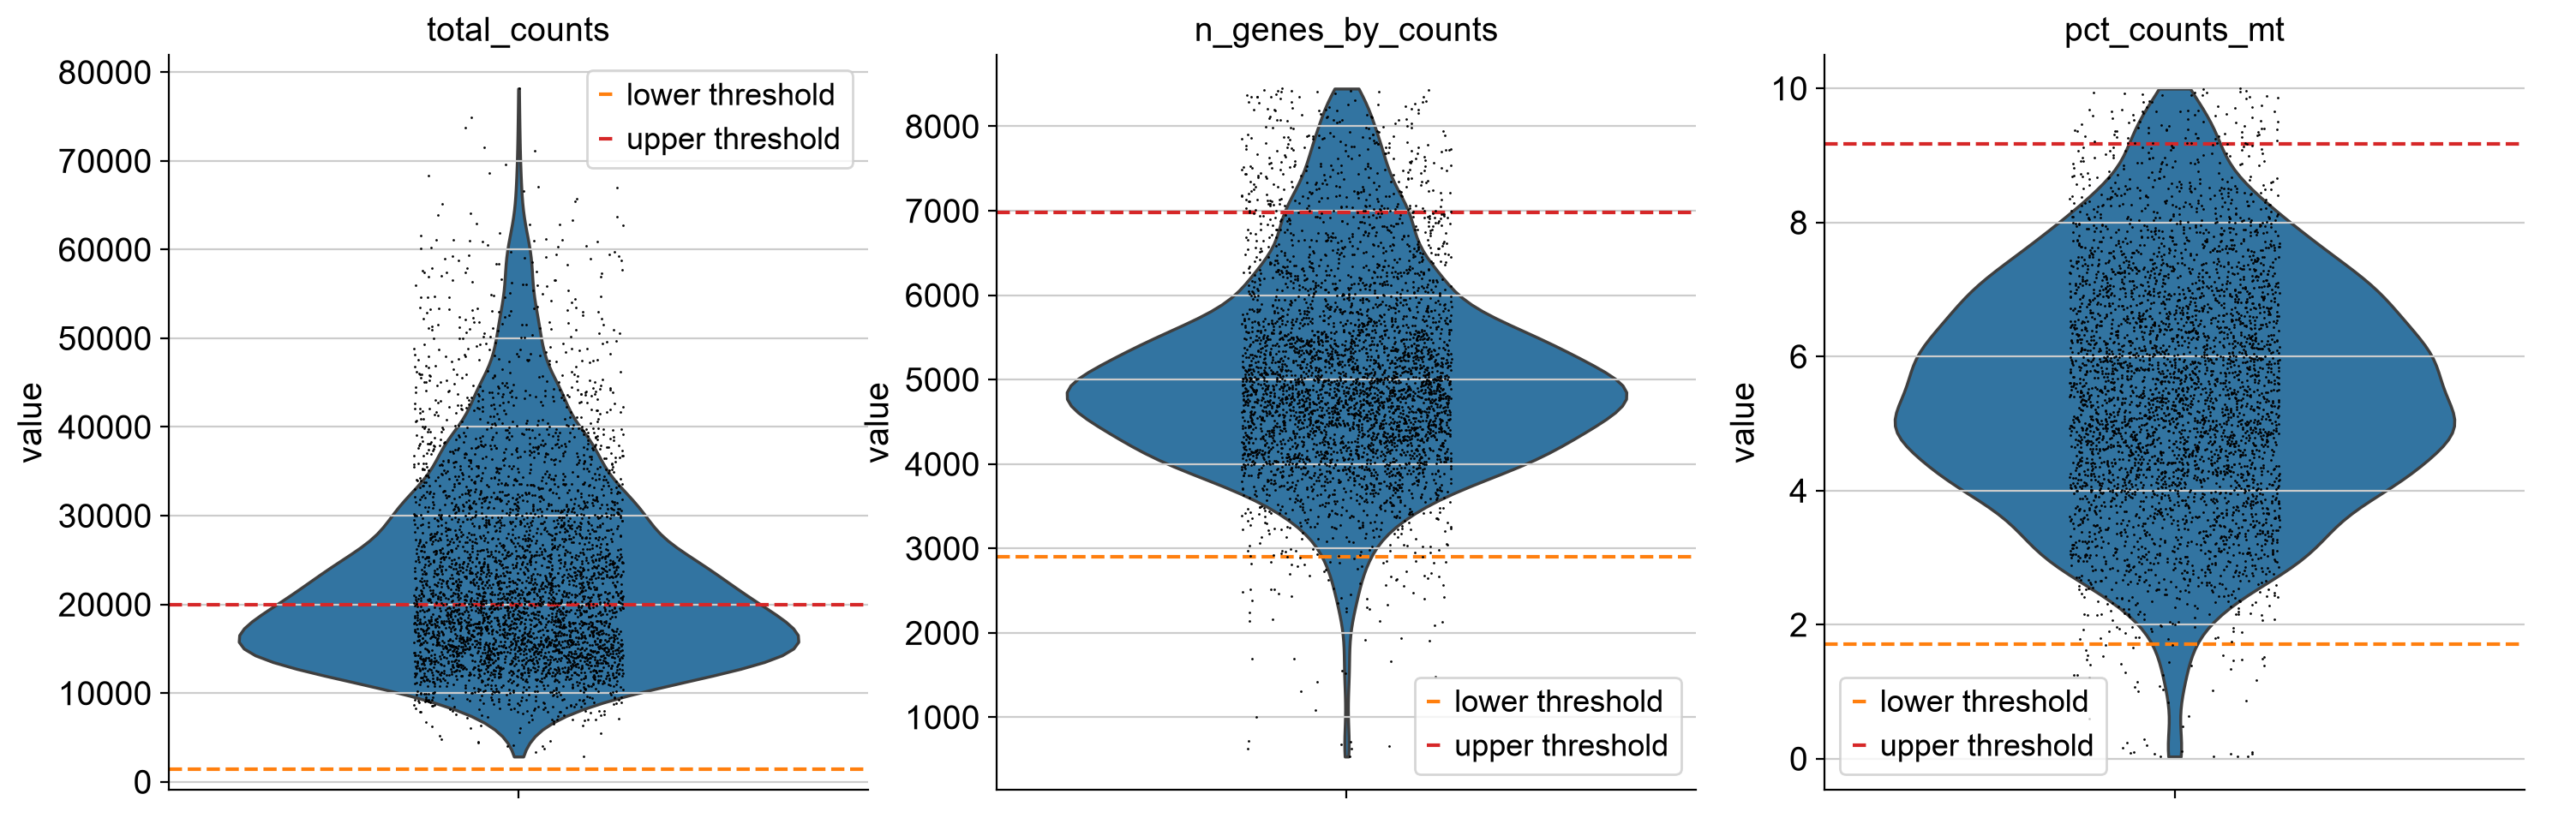

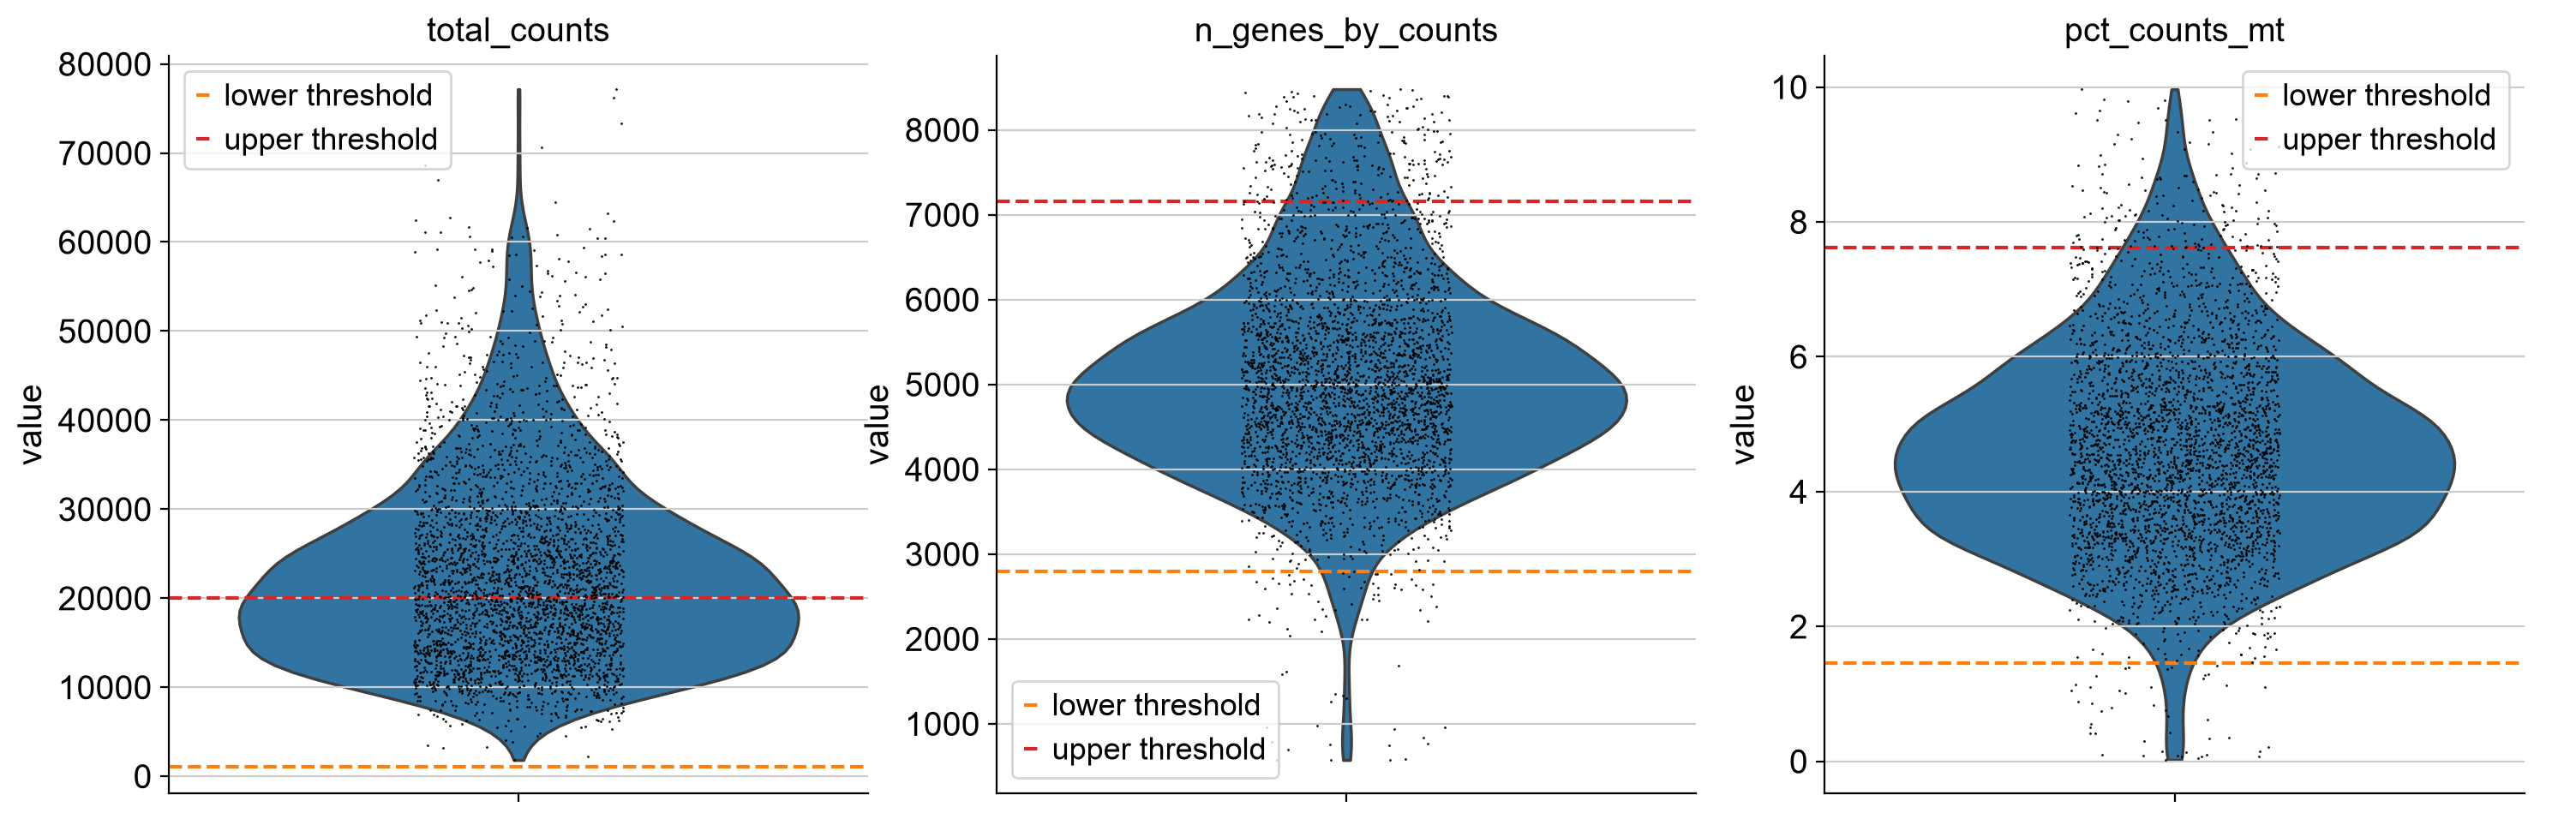

In [25]:
for sample, thresholds in per_sample_thresholds.items():
    fig, axes = plot_thresholds(
        subset_adata(adata, mask=adata.obs[SAMPLE_KEY].eq(sample)),
        thresholds=thresholds,
    )

In [26]:
print(
    adata.obs[["total_counts", "n_genes_by_counts", "pct_counts_mt"]]
    .describe()
    .round(1)
)

       total_counts  n_genes_by_counts  pct_counts_mt
count       21870.0            21870.0        21870.0
mean        24978.3             5053.2            4.8
std         14598.7             1598.5            1.7
min          1506.0              533.0            0.0
25%         14400.5             4122.0            3.6
50%         23045.5             5080.0            4.6
75%         33559.8             6142.8            5.9
max         79794.0             8499.0           10.0


---
## Step 4 — Set filtering thresholds (Strict Filtering)

**Adjust the values below based on the distributions you saw before.**  

In [27]:
# ── Adjust these thresholds based on your data distributions ──────────────────
MIN_GENES = global_thresholds["n_genes_by_counts"][0]
MAX_GENES = global_thresholds["n_genes_by_counts"][1]
MIN_COUNTS = global_thresholds["total_counts"][0]
MAX_COUNTS = global_thresholds["total_counts"][1]
MAX_MITO = global_thresholds["pct_counts_mt"][1]
MIN_CELLS = 3  # minimum number of cells in which a gene must be expressed
# ─────────────────────────────────────────────────────────────────────────────

adata_qc = filter_cells_and_genes(
    adata,
    min_genes=MIN_GENES,
    min_cells=MIN_CELLS,
    max_genes=MAX_GENES,
    min_counts=MIN_COUNTS,
    max_counts=MAX_COUNTS,
    max_mito=MAX_MITO
)

2026-10-18 16:38:12.497 | INFO     | besca_sc.pp._filter:filter_cells_and_genes:110 - started with 21870 cells and 38606 genes
2026-10-18 16:38:12.508 | INFO     | besca_sc.pp._filter:filter_cells_and_genes:132 - removed 14449 cells
2026-10-18 16:38:12.943 | INFO     | besca_sc.pp._filter:filter_cells_and_genes:139 - removed 6246 genes
2026-10-18 16:38:13.370 | INFO     | besca_sc.pp._filter:filter_cells_and_genes:142 - finished with 7421 cells and 32360 genes


---
## Step 5 — Save

Before saving, we copy the current counts into a dedicated layer called `counts`.  
This preserves the original CellBender-corrected values so that downstream tools (doublet detection, normalisation) always have access to unmodified counts — even after `adata.X` is later overwritten by normalisation.

In [28]:
adata_qc

AnnData object with n_obs × n_vars = 7421 × 32360
    obs: 'htodemux_Assignment', 'multiseq_Assignment', 'hasheddrops_Assignment', 'gmmdemux_Assignment', 'hashsolo_Assignment', 'bff_consensuscall_Assignment', 'demuxmix_Assignment', 'Consensus_Assignment', 'Confidence', 'Consensus_DropletType', 'Donor', 'stimulation', 'library', 'sample_id', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'scrublet_score', 'scrublet_predicted_doublet', 'solo_doublet_probability', 'solo_prediction', 'is_doublet'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    uns: 'doublet_detection', 'sample_id_colors'
    obsm: 'X_pca', 'X_umap'
    layers: 'counts', None (.X)

In [29]:
out_path = f"{PROCESSED_DIR}/final_qc_merged.h5ad"
adata_qc.write_h5ad(out_path)
print(f"Saved: {out_path}")
print(f"  {adata_qc.n_obs} cells  x  {adata_qc.n_vars} genes")
print(f"  Layers: {list(adata_qc.layers.keys())}")

Saved: /Users/adaml9/besca_sc/data/processed/final_qc_merged.h5ad
  7421 cells  x  32360 genes
  Layers: ['counts', None]
